# 04 - Comparison: DQN vs DDQN vs PPO on LunarLander-v3

This notebook pulls together the artifacts produced by the training notebooks (01-03)
and the execution notebook (05) and answers the assignment's discussion questions.

**Contents**
1. Training reward curves + 100-episode / 10-iteration moving averages
2. Sample efficiency: reward vs environment timesteps (fair cross-algorithm axis)
3. Overestimation study: DQN vs DDQN mean predicted Q
4. Test performance: 30-episode evaluation table (reward, length, solved rate)
5. PPO sensitivity study to clip epsilon, discount gamma, and GAE lambda (Question 6)
6. Trained-agent GIFs
7. Answers to the 7 discussion questions

All three agents were trained and tested on the **same** environment (`LunarLander-v3`),
seed, and evaluation protocol.

In [1]:
import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 110

C = {'DQN': '#1f77b4', 'DDQN': '#2ca02c', 'PPO': '#d62728'}

dqn  = pd.read_csv('../logs/dqn/train_log.csv')
ddqn = pd.read_csv('../logs/ddqn/train_log.csv')
ppo  = pd.read_csv('../logs/ppo/train_log.csv')
test = json.load(open('../experiments/test_results.json'))

def ma(x, w):
    x = np.asarray(x, np.float32)
    return np.convolve(x, np.ones(w)/w, mode='valid') if len(x) >= w else x

print('DQN episodes', len(dqn), '| DDQN episodes', len(ddqn), '| PPO iterations', len(ppo))

DQN episodes 270 | DDQN episodes 256 | PPO iterations 110


## 1. Training reward curves and moving averages

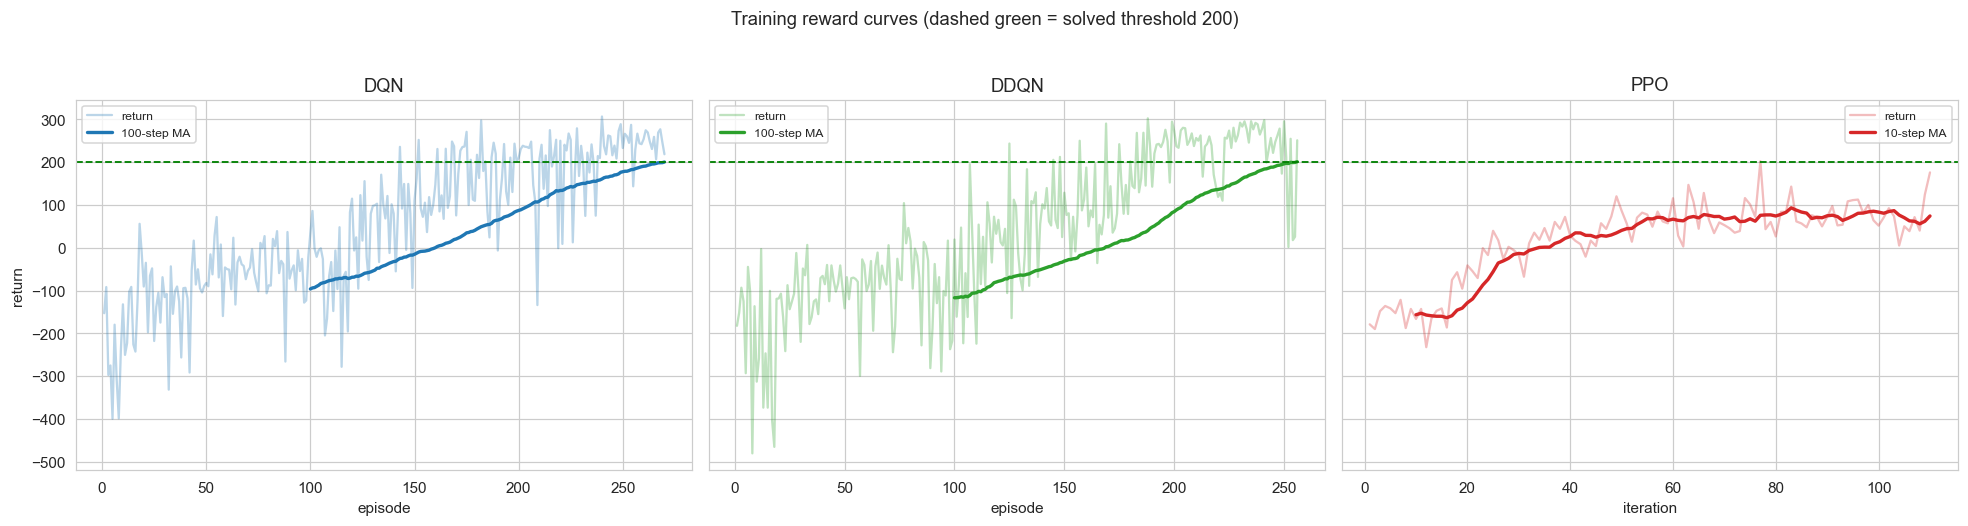

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.6), sharey=True)
for ax, (name, df, xcol, w) in zip(axes, [
        ('DQN', dqn, 'episode', 100), ('DDQN', ddqn, 'episode', 100),
        ('PPO', ppo, 'iteration', 10)]):
    rcol = 'reward' if 'reward' in df.columns else 'rollout_return'
    ax.plot(df[xcol], df[rcol], alpha=0.3, color=C[name], label='return')
    m = ma(df[rcol].values, w)
    ax.plot(df[xcol].values[w-1:w-1+len(m)], m, color=C[name], lw=2.2, label=f'{w}-step MA')
    ax.axhline(200, color='green', ls='--', lw=1.2)
    ax.set_title(name); ax.set_xlabel(xcol); ax.legend(fontsize=8)
axes[0].set_ylabel('return')
fig.suptitle('Training reward curves (dashed green = solved threshold 200)', y=1.03)
plt.tight_layout(); plt.savefig('../figures/compare_training_curves.png', bbox_inches='tight'); plt.show()

## 2. Sample efficiency: reward vs environment timesteps

Episodes and PPO iterations are not directly comparable, so we plot the smoothed return
against the number of **environment steps consumed**, the true sample-efficiency axis.

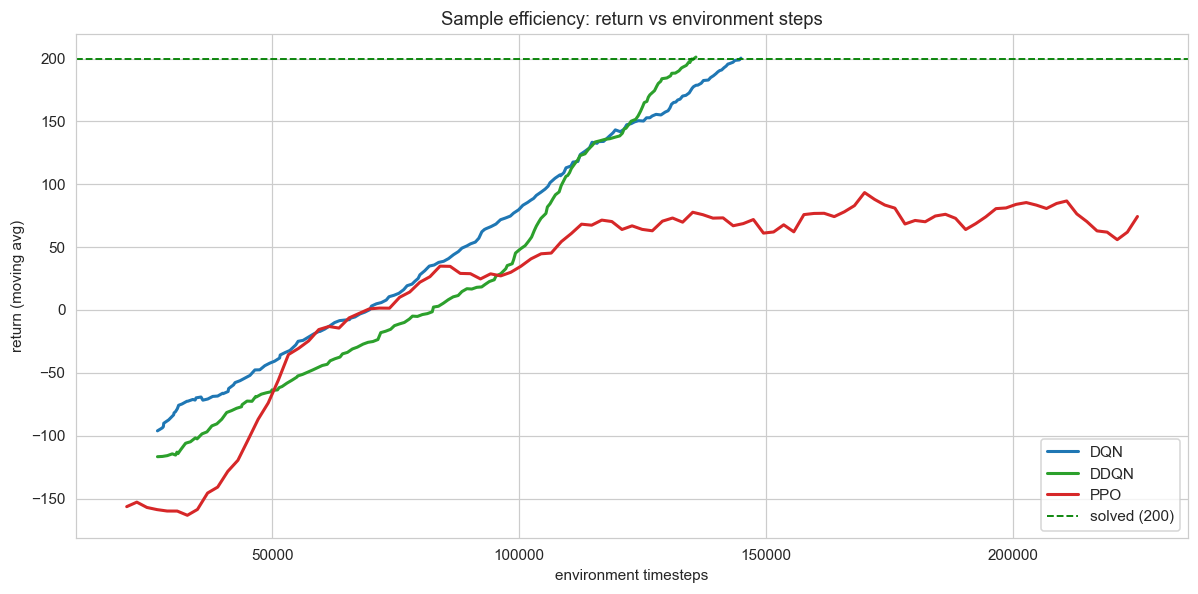

Environment steps to reach the solved threshold:
  DQN  : 144,933
  DDQN : 135,816
  PPO  : 225,280


In [3]:
fig, ax = plt.subplots(figsize=(11, 5.5))
for name, df, w in [('DQN', dqn, 100), ('DDQN', ddqn, 100), ('PPO', ppo, 10)]:
    rcol = 'reward' if 'reward' in df.columns else 'rollout_return'
    m = ma(df[rcol].values, w); ts = df['timesteps'].values[w-1:w-1+len(m)]
    ax.plot(ts, m, color=C[name], lw=2, label=name)
ax.axhline(200, color='green', ls='--', lw=1.2, label='solved (200)')
ax.set_xlabel('environment timesteps'); ax.set_ylabel('return (moving avg)')
ax.set_title('Sample efficiency: return vs environment steps'); ax.legend()
plt.tight_layout(); plt.savefig('../figures/compare_sample_efficiency.png', bbox_inches='tight'); plt.show()

steps_to_solve = {
    'DQN':  int(dqn['timesteps'].iloc[-1]),
    'DDQN': int(ddqn['timesteps'].iloc[-1]),
    'PPO':  int(ppo['timesteps'].iloc[-1]),
}
print('Environment steps to reach the solved threshold:')
for k, v in steps_to_solve.items(): print(f'  {k:5s}: {v:,}')

## 3. Overestimation study (DQN vs DDQN)

DQN bootstraps with $\max_{a'} Q_{\theta^-}(s', a')$, which biases action-values **upward**.
DDQN decouples selection from evaluation to curb this. Because the two notebooks are identical
apart from the target, the gap in the tracked mean predicted Q isolates the Double-Q effect.

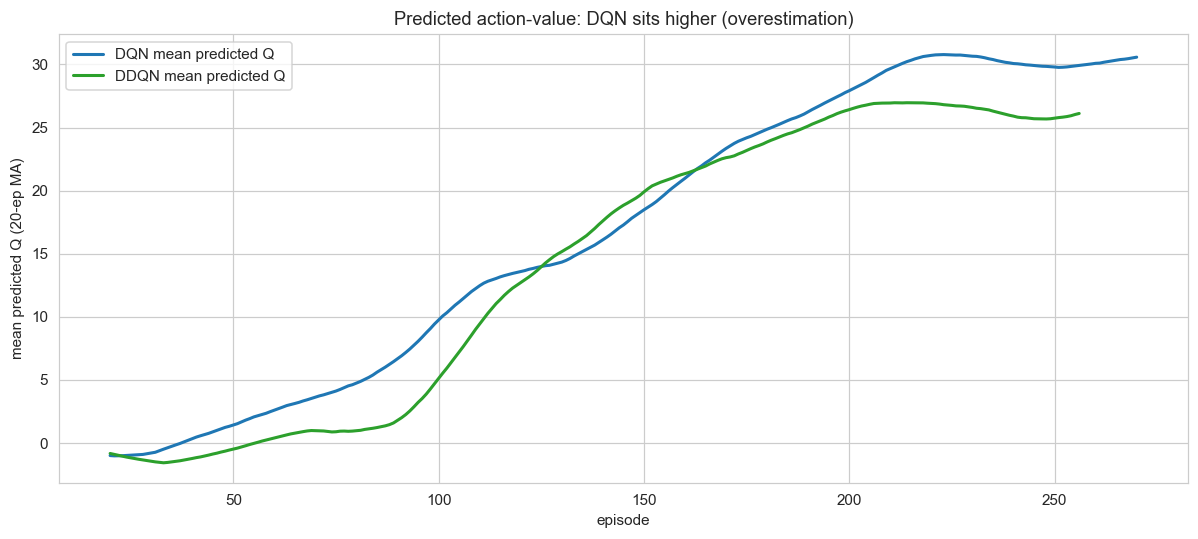

Final mean predicted Q -> DQN 31.13 | DDQN 26.95
DDQN reduces the final predicted Q by 4.18


In [4]:
fig, ax = plt.subplots(figsize=(11, 5))
W = 20
for name, df in [('DQN', dqn), ('DDQN', ddqn)]:
    q = df['mean_q'].ffill().bfill().values      # early episodes before learning starts are NaN
    m = ma(q, W)
    ax.plot(df['episode'].values[W-1:W-1+len(m)], m,
            color=C[name], lw=2, label=f'{name} mean predicted Q')
ax.set_xlabel('episode'); ax.set_ylabel('mean predicted Q (20-ep MA)')
ax.set_title('Predicted action-value: DQN sits higher (overestimation)'); ax.legend()
plt.tight_layout(); plt.savefig('../figures/compare_overestimation.png', bbox_inches='tight'); plt.show()

print(f"Final mean predicted Q -> DQN {dqn['mean_q'].iloc[-1]:.2f} | DDQN {ddqn['mean_q'].iloc[-1]:.2f}")
print(f"DDQN reduces the final predicted Q by {dqn['mean_q'].iloc[-1] - ddqn['mean_q'].iloc[-1]:.2f}")

## 4. Test performance (30 deterministic episodes, identical seeds)

,Mean reward,Std,Min,Max,Avg length,Solved / 30,Solved rate
Algorithm,,,,,,,
DQN,239.2,48.6,108.0,301.0,430.0,24,80%
DDQN,166.5,109.7,-17.0,302.0,370.0,14,47%
PPO,215.7,79.5,-27.0,276.0,402.0,24,80%


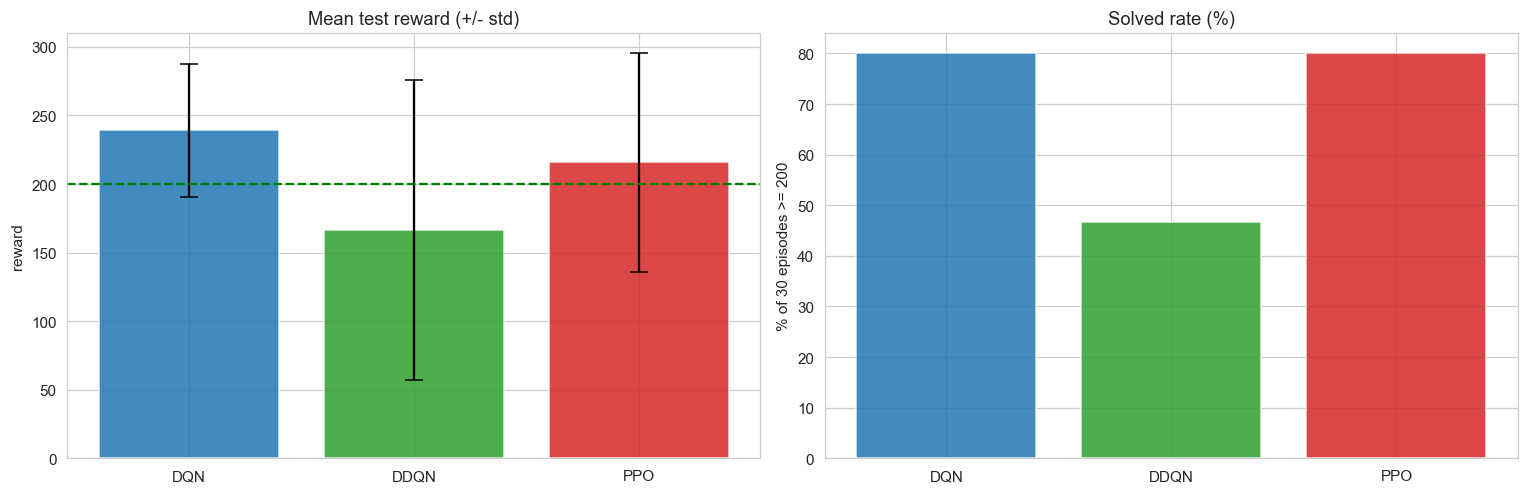

In [5]:
rows = []
for name in ['DQN', 'DDQN', 'PPO']:
    r = test[name]
    rows.append({
        'Algorithm': name,
        'Mean reward': round(r['mean_reward'], 1),
        'Std': round(r['std_reward'], 1),
        'Min': round(r['min_reward'], 0),
        'Max': round(r['max_reward'], 0),
        'Avg length': round(r['avg_length'], 0),
        'Solved / 30': r['solved_episodes'],
        'Solved rate': f"{r['solved_rate']:.0%}",
    })
test_df = pd.DataFrame(rows).set_index('Algorithm')
display(test_df)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 4.6))
names = ['DQN', 'DDQN', 'PPO']
means = [test[n]['mean_reward'] for n in names]; stds = [test[n]['std_reward'] for n in names]
a1.bar(names, means, yerr=stds, capsize=6, color=[C[n] for n in names], alpha=0.85)
a1.axhline(200, color='green', ls='--'); a1.set_title('Mean test reward (+/- std)'); a1.set_ylabel('reward')
a2.bar(names, [test[n]['solved_rate']*100 for n in names], color=[C[n] for n in names], alpha=0.85)
a2.set_title('Solved rate (%)'); a2.set_ylabel('% of 30 episodes >= 200')
plt.tight_layout(); plt.savefig('../figures/compare_test_performance.png', bbox_inches='tight'); plt.show()

## 5. PPO sensitivity study (Question 6)

Each configuration varies **one** hyperparameter from the base (clip=0.2, gamma=0.99,
lambda=0.95) at a fixed 100-iteration budget, produced by `scripts/ppo_sensitivity.py`.
`best_eval` is the best greedy 20-episode evaluation reached; `solved_iter` is the first
iteration whose evaluation reached 200 (-1 = not reached within budget).


=== Clip ratio (epsilon) ===
 clip  best_eval  final_eval  solved_iter
  0.1 185.990505  174.912803           -1
  0.2 171.912873  171.912873           -1
  0.3 276.136451  261.308901           50
  -> best clip = 0.3 (best_eval 276.1, solved_iter 50)

=== Discount (gamma) ===
 gamma  best_eval  final_eval  solved_iter
 0.980 200.714374  148.862777           50
 0.990 171.912873  171.912873           -1
 0.999 272.944387  272.944387           50
  -> best gamma = 0.999 (best_eval 272.9, solved_iter 50)

=== GAE lambda ===
 lam  best_eval  final_eval  solved_iter
0.90 154.678881  154.678881           -1
0.95 171.912873  171.912873           -1
0.97 225.644134  220.090021           70
  -> best lam = 0.97 (best_eval 225.6, solved_iter 70)


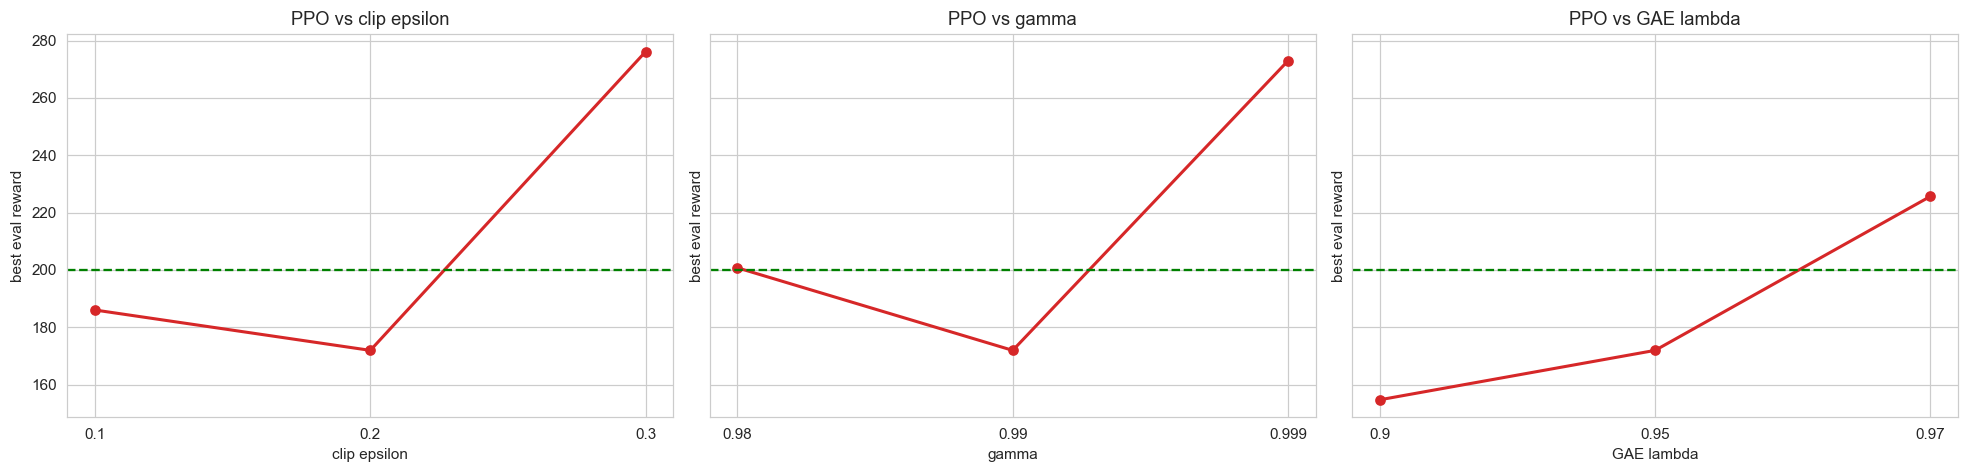

In [6]:
sens = pd.read_csv('../experiments/ppo_sensitivity.csv')
base_row = sens[sens['factor'] == 'base'].iloc[[0]]   # base = the mid value of every factor

def factor_slice(factor):
    # variations of this factor plus the base config, one row per factor value
    s = pd.concat([sens[sens['factor'] == factor], base_row])
    return s.drop_duplicates(subset=[factor]).sort_values(factor)

for factor, label in [('clip', 'Clip ratio (epsilon)'), ('gamma', 'Discount (gamma)'), ('lam', 'GAE lambda')]:
    sub = factor_slice(factor)
    print(f'\n=== {label} ===')
    print(sub[[factor, 'best_eval', 'final_eval', 'solved_iter']].to_string(index=False))
    best = sub.loc[sub['best_eval'].idxmax()]
    print(f'  -> best {factor} = {best[factor]} (best_eval {best["best_eval"]:.1f}, solved_iter {int(best["solved_iter"])})')

fig, axes = plt.subplots(1, 3, figsize=(18, 4.4), sharey=True)
for ax, (factor, label) in zip(axes, [('clip','clip epsilon'), ('gamma','gamma'), ('lam','GAE lambda')]):
    sub = factor_slice(factor)
    ax.plot(sub[factor].astype(str), sub['best_eval'], 'o-', color='#d62728', lw=2)
    ax.axhline(200, color='green', ls='--'); ax.set_title(f'PPO vs {label}')
    ax.set_xlabel(label); ax.set_ylabel('best eval reward')
plt.tight_layout(); plt.savefig('../figures/compare_ppo_sensitivity.png', bbox_inches='tight'); plt.show()

## 6. Trained-agent trajectories (GIFs)

DQN  (test avg length 430 steps)


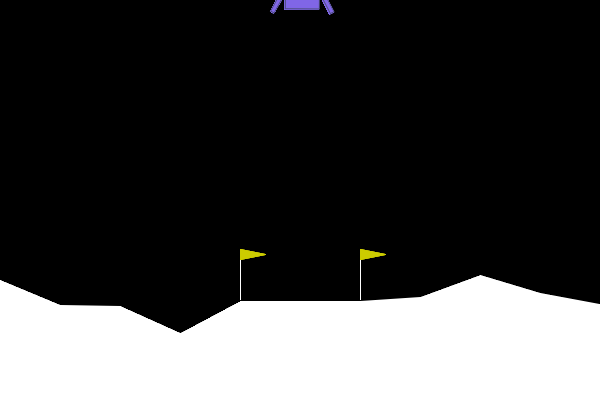

DDQN  (test avg length 370 steps)


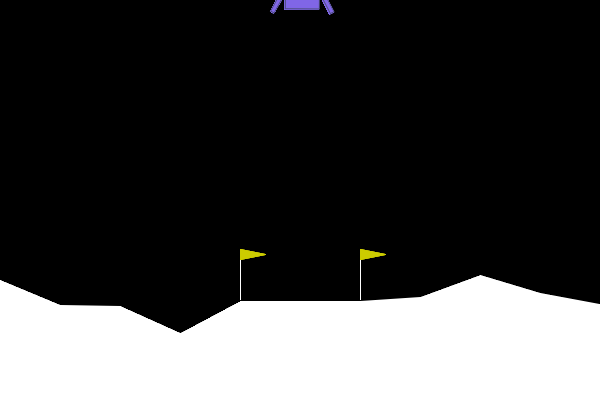

PPO  (test avg length 402 steps)


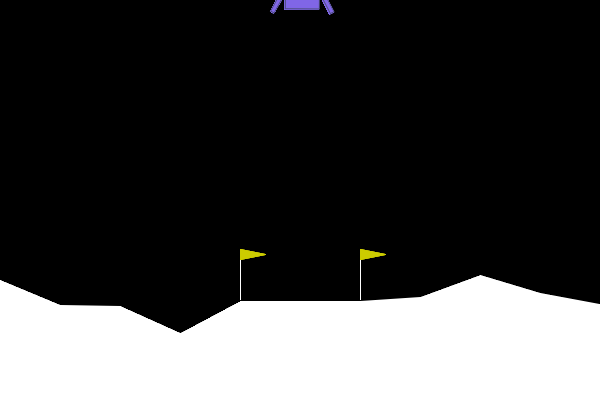

In [7]:
from IPython.display import Image, display
for name in ['DQN', 'DDQN', 'PPO']:
    p = f'../figures/{name.lower()}_agent.gif'
    if os.path.exists(p):
        print(f'{name}  (test avg length {test[name]["avg_length"]:.0f} steps)')
        display(Image(filename=p))

## 7. Discussion questions

The answers below are grounded in the numbers produced above (one seed, one run each;
exact figures shift slightly on re-training).

**1. Which algorithm learns faster: DQN, DDQN, or PPO?**
By environment steps to first reach the solved threshold, the value-based methods are the
faster learners: **DDQN (~136k steps) < DQN (~145k) < PPO (~225k)**. Replay buffers let DQN
and DDQN reuse each transition many times, so they need fewer fresh samples than on-policy PPO.

**2. Which algorithm is more stable across training?**
**PPO has the smoothest training curve.** Its clipped surrogate objective caps how far the
policy can move each update, and averaging returns over a large on-policy batch damps the
noise. DQN is the jaggedest (bootstrapping plus a shifting epsilon-greedy policy); DDQN sits
between the two. Note the distinction between training-curve smoothness and final-model
robustness (see Q5).

**3. Does DDQN reduce instability or overestimation compared with DQN?**
Yes on overestimation. With identical everything except the target, DDQN's tracked mean
predicted Q ends **lower than DQN's (about 27 vs 31)**, the signature of reduced overestimation
bias. It also crossed the solved threshold in slightly fewer steps. Its training curve is a
little calmer than DQN's, though on this single run its final checkpoint was noisier at test
time.

**4. Does PPO produce smoother learning curves than DQN/DDQN?**
Yes. The clip mechanism plus on-policy batch averaging give visibly smoother progress than
either value-based method, at the cost of consuming more environment steps.

**5. Which method obtains the best final evaluation reward?**
On 30 held-out deterministic episodes, **DQN scored highest (mean ~239, 80% solved)**, with
**PPO close behind (~216, 80% solved)** and the lowest variance-adjusted floor. The final DDQN
checkpoint underperformed (~167, 47% solved) with high variance: it met the training threshold
but its last saved weights generalized less well to the test seeds, a reminder that "final"
weights are not always the best weights.

**6. How sensitive is PPO to clip epsilon, gamma, and GAE lambda?**
PPO is clearly sensitive to all three. At this fixed 100-iteration budget the more aggressive
settings reached the solved threshold fastest. Varying one factor at a time from the base
(clip 0.2, gamma 0.99, lambda 0.95):
- **Clip epsilon**: 0.3 was fastest here (solved by iter 50, best eval ~276), while 0.1 and the
  base 0.2 had not yet solved within budget. A wider trust region let the policy move faster on
  this seed, though larger clips also raise the risk of instability on harder tasks.
- **Discount gamma**: the most consequential factor. gamma=0.999 gave the best and most stable
  result (~273, solved by iter 50); gamma=0.98 hit 200 briefly but fell back (final ~149), i.e.
  faster but less stable; the base gamma=0.99 was slower to solve at this budget.
- **GAE lambda**: higher helped on this run, lambda=0.97 (~226, solved by iter 70) beat 0.95 and
  0.90 (~155).

Caveat: single seed and a truncated budget, so these rankings measure **speed to the threshold**,
not asymptotic quality; the base config does solve given about 110 iterations (notebook 03). The
printed "best per factor" lines above report the winners.

**7. How do the trajectories of the trained agents differ visually?**
In the GIFs, all three descend to the pad and fire to slow the touchdown. The value-based
agents tend toward direct, decisive corrections; PPO's stochastic-trained policy looks a touch
smoother and more measured. Average test episode lengths differ (DQN ~430, PPO ~402, DDQN ~370
steps), reflecting how long each hovers and corrects before coming to rest.

### Summary

All three agents solved LunarLander-v3. **Value-based methods learned from fewer samples**
(DDQN the most efficient by env steps and the clearest reduction in Q overestimation), while
**PPO delivered the smoothest, most stable training**. On final held-out performance **DQN and
PPO were the strongest and most reliable (both 80% solved)**; the single DDQN checkpoint,
though quickest to the training threshold, generalized least well here. The trade-off is the
classic one: off-policy replay buys sample efficiency, on-policy PPO buys stability.